In [1]:
from cnn_project.utils.data_loader import load_datasets
from cnn_project.constants import TRAIN_DATA_C, TEST_DATA_C

In [2]:
(train_ds, test_ds, class_names) = load_datasets(train_dir=TRAIN_DATA_C, test_dir=TEST_DATA_C)

Found 5000 files belonging to 4 classes.
Found 1000 files belonging to 4 classes.


In [3]:
print(type(train_ds))
print(train_ds.element_spec)

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
(TensorSpec(shape=(None, 150, 150, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [4]:
images, labels = next(iter(train_ds))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Images shape: (32, 150, 150, 1)
Labels shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>


In [11]:
print(labels[:10].numpy())

[3 3 1 1 2 1 3 2 3 0]


In [5]:
num_batches = sum(1 for _ in train_ds)
print("Number of batches:", num_batches)

Number of batches: 157


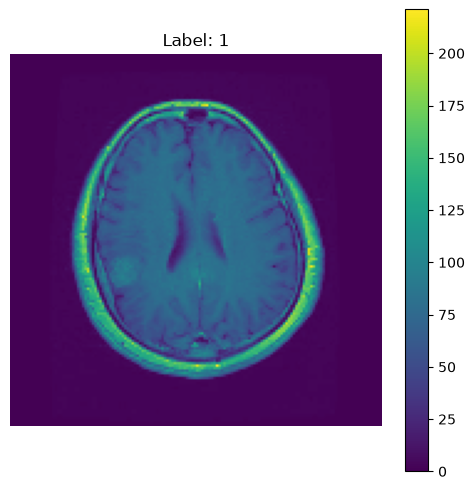

In [6]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

fig, ax = plt.subplots(figsize=(6, 6))

im = ax.imshow(images[0].numpy().astype("uint8"))

ax.set_title(f"Label: {labels[0].numpy()}")
ax.axis("off")

fig.colorbar(im, ax=ax)

plt.show()

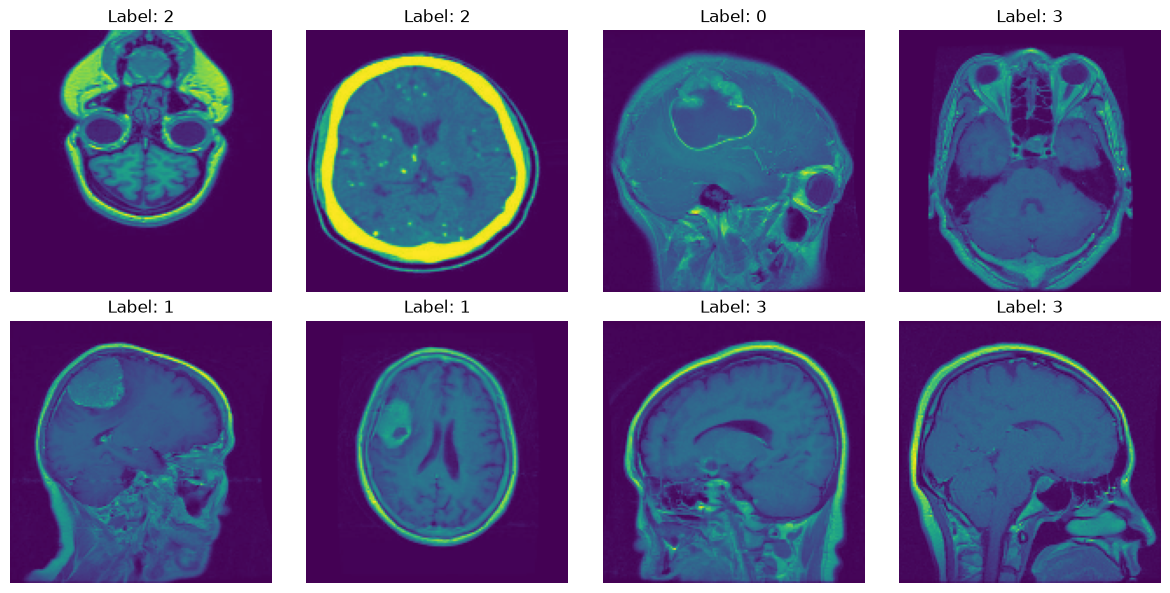

In [7]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy().astype("uint8"))
    ax.set_title(f"Label: {labels[i].numpy()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

In [17]:
df = pd.read_json("../DATA/manifest.json")

In [18]:
df

,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15581,segmentation_task\train\masks\brisc2025_train_...,brisc2025_train_04996_pi_sa_t1.png,segmentation,train,4996,pi,pituitary,sa,sagittal,T1,True,segmentation_task\train\images\brisc2025_train...,512,512,1905,2a21b781138c8c9503e61e217cdf685b1edbbc6d83a72f...
15582,segmentation_task\train\masks\brisc2025_train_...,brisc2025_train_04997_pi_sa_t1.png,segmentation,train,4997,pi,pituitary,sa,sagittal,T1,True,segmentation_task\train\images\brisc2025_train...,512,512,1848,802a80490a7c65306f2b9e377f6d0be89e3258091d9470...
15583,segmentation_task\train\masks\brisc2025_train_...,brisc2025_train_04998_pi_sa_t1.png,segmentation,train,4998,pi,pituitary,sa,sagittal,T1,True,segmentation_task\train\images\brisc2025_train...,512,512,1806,a00aba05c57e753e0605828b1d2b4eb7ef53f5ecb8c777...
15584,segmentation_task\train\masks\brisc2025_train_...,brisc2025_train_04999_pi_sa_t1.png,segmentation,train,4999,pi,pituitary,sa,sagittal,T1,True,segmentation_task\train\images\brisc2025_train...,512,512,1891,223dc687ebb83bef9b4f0af481658256edd1a51026e478...


<Axes: xlabel='tumor_label'>

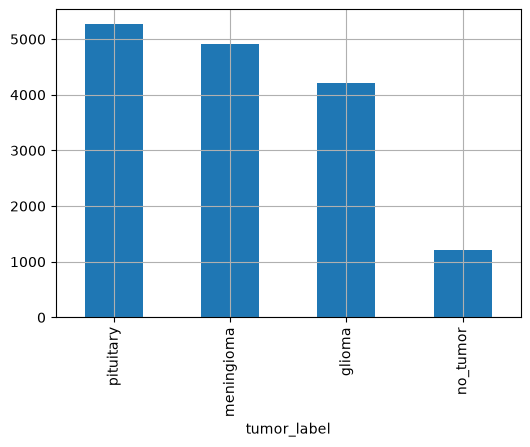

In [ ]:
df["tumor_label"].value_counts().plot(kind="bar", figsize=(6, 4), grid=True)

In [31]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>